# Giai đoạn 2 — Xây Dựng Trí Tuệ (Offline Training)

Notebook này triển khai đúng **mục 3, Giai đoạn 2** trong *Tài Liệu Thiết Kế: Hệ Thống Gợi Ý Hybrid Cho Sàn Thương Mại Điện Tử Laptop*:

1. **Chạy SBERT** — đọc thông số kỹ thuật từ collection sản phẩm, mã hoá thành `content_vector` (384 chiều).
2. **Chạy ALS** — đọc collection `interactions`, phân tích hành vi (implicit feedback), sinh `cf_vector` cho từng sản phẩm.
3. **Cập nhật Vector & Index** — lưu 2 vector này **ngược lại vào MongoDB Atlas** và kích hoạt Vector Search Index.

**Khác biệt quan trọng so với các bản trước:** theo đúng thiết kế, mục 2.3 nói rõ *"Mô hình không gộp Vector lúc huấn luyện mà tính điểm độc lập và kết hợp tại bước phục vụ trực tuyến (Online Serving)"* — nên notebook này **chỉ lưu `cf_vector` và `content_vector` riêng biệt**, **không** train/lưu một vector hybrid gộp sẵn. Công thức `Score_Final = α×Score_CF + (1-α)×Score_Content` sẽ được áp dụng ở tầng Backend (Node.js) lúc re-ranking — notebook chỉ đề xuất một giá trị `α` mặc định hợp lý dựa trên đánh giá offline.

**⚠️ Giả định cần bạn xác nhận:** tài liệu gọi collection sản phẩm là `Laptops`, nhưng theo các notebook trước bạn đã dùng thực tế là **`db.products`** và **`db.interactions`** — notebook này giữ nguyên tên collection đã chạy thành công trước đó. Nếu bạn đã đổi tên, sửa lại `PRODUCTS_COLL` / `INTERACTIONS_COLL` ở Bước 1.

## Thiết lập BẮT BUỘC trên Kaggle (làm 1 lần)
1. **Add-ons → Secrets** → thêm secret `MONGODB_URI`, bật **Attach to notebook**.
2. **Settings** → bật **Internet: On**.

**CẢNH BÁO:** notebook này **ghi (write)** vào database thật ở Bước 10 — mặc định `DRY_RUN = True` để an toàn, chỉ ghi thật khi bạn chủ động đặt `DRY_RUN = False`.

## Bước 1: Cài đặt thư viện & Kết nối MongoDB Atlas

In [1]:
!pip install -q pymongo dnspython implicit scikit-learn sentence-transformers joblib matplotlib tqdm


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 9.2 MB/s eta 0:00:00


In [2]:
import os

DEBUG_CONNECTION = False   # bật True nếu connect_mongo() không tìm ra URI, để xem lỗi gốc từng bước
PRODUCTS_COLL = "products"          # đổi thành "laptops" nếu bạn dùng đúng tên trong tài liệu
INTERACTIONS_COLL = "interactions"

def connect_mongo(secret_name="MONGODB_URI", env_path="backend/.env"):
    from pymongo import MongoClient
    uri = None
    try:
        from kaggle_secrets import UserSecretsClient
        uri = UserSecretsClient().get_secret(secret_name)
        print("Lấy MONGODB_URI từ Kaggle Secrets.")
    except Exception as e:
        if DEBUG_CONNECTION:
            print(f"[debug] Không lấy được từ Kaggle Secrets: {e}")
    if not uri:
        uri = os.getenv("MONGODB_URI")
        if uri:
            print("Lấy MONGODB_URI từ biến môi trường.")
    if not uri:
        try:
            from dotenv import load_dotenv
            load_dotenv(env_path)
            uri = os.getenv("MONGODB_URI")
            if uri:
                print(f"Lấy MONGODB_URI từ file {env_path}.")
        except Exception as e:
            if DEBUG_CONNECTION:
                print(f"[debug] Không đọc được {env_path}: {e}")
    assert uri, "Không tìm thấy MONGODB_URI. Thêm Kaggle Secret (Add-ons > Secrets) trước khi chạy."
    client = MongoClient(uri)
    db = client.get_default_database()
    print(f"Kết nối thành công tới database: {db.name}")
    return db

db = connect_mongo()
products_col = db[PRODUCTS_COLL]
interactions_col = db[INTERACTIONS_COLL]


Lấy MONGODB_URI từ Kaggle Secrets.
Kết nối thành công tới database: root_laptops


## Bước 2: Chẩn đoán dữ liệu đầu vào

Kiểm tra nhanh trước khi train — collection `interactions` phải đã có dữ liệu (thật hoặc mô phỏng từ Giai đoạn 1 của tài liệu), và `products`/`laptops` phải có thông tin cấu hình để SBERT đọc.

In [3]:
import pandas as pd

n_products = products_col.count_documents({})
n_interactions = interactions_col.count_documents({})
n_users_with_interactions = len(interactions_col.distinct("userId"))

print(f"Số sản phẩm: {n_products}")
print(f"Số tương tác: {n_interactions}")
print(f"Số user có tương tác: {n_users_with_interactions}")

type_dist = list(interactions_col.aggregate([{"$group": {"_id": "$type", "count": {"$sum": 1}}}]))
print("\nPhân bố theo loại tương tác:")
for row in sorted(type_dist, key=lambda r: -r["count"]):
    label = row["_id"] if row["_id"] is not None else "(không có type)"
    print(f"  {label:<20} {row['count']:>8,}")

result = list(interactions_col.aggregate([
    {"$group": {"_id": "$userId", "n": {"$sum": 1}}},
    {"$match": {"n": {"$gte": 2}}},
    {"$count": "n_users_trainable"}
]))
n_trainable_users = result[0]["n_users_trainable"] if result else 0
print(f"\nSố user có >= 2 tương tác (đủ điều kiện train/test): {n_trainable_users}")

MIN_TRAINABLE_USERS = 30
if n_trainable_users < MIN_TRAINABLE_USERS:
    print(f"\nLƯU Ý: {n_trainable_users} < {MIN_TRAINABLE_USERS} — kết quả đánh giá bên dưới vẫn "
          "chạy được nhưng độ tin cậy thống kê thấp do mẫu nhỏ.")

assert n_products > 0, f"Collection `{PRODUCTS_COLL}` rỗng — kiểm tra lại PRODUCTS_COLL ở Bước 1."
assert n_interactions > 0, f"Collection `{INTERACTIONS_COLL}` rỗng — chạy Giai đoạn 1 (sinh dữ liệu) trước."


Số sản phẩm: 398
Số tương tác: 2918
Số user có tương tác: 56

Phân bố theo loại tương tác:
  view                    1,593
  like                      652
  search_click              364
  add_to_cart               255
  purchase                   54

Số user có >= 2 tương tác (đủ điều kiện train/test): 56


## Bước 2b: EDA & Trực quan hoá dữ liệu từ MongoDB

Khám phá dữ liệu thô (trước khi encode/train) trực tiếp từ `interactions` và `products`, để hiểu hành vi người dùng và độ phủ dữ liệu trước khi train.

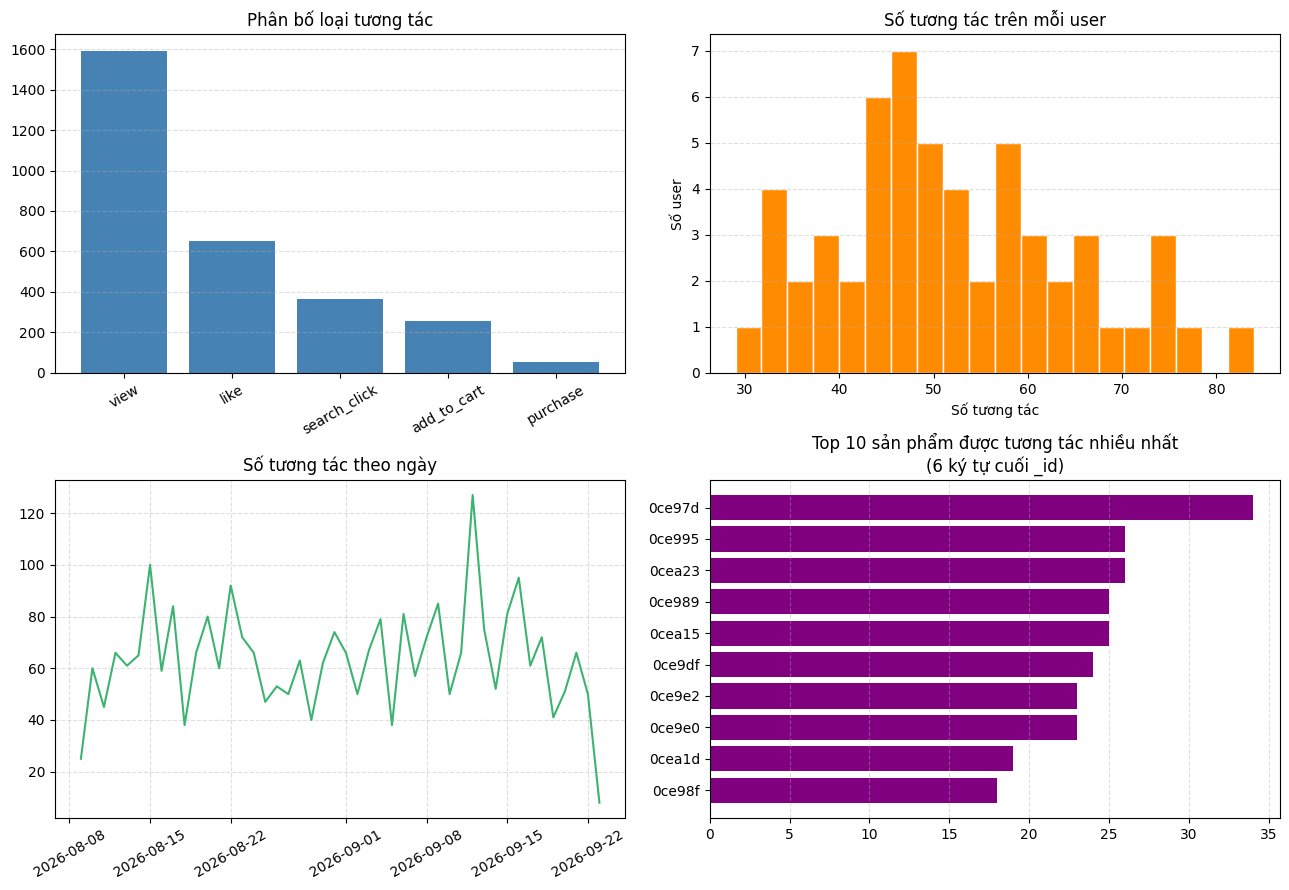

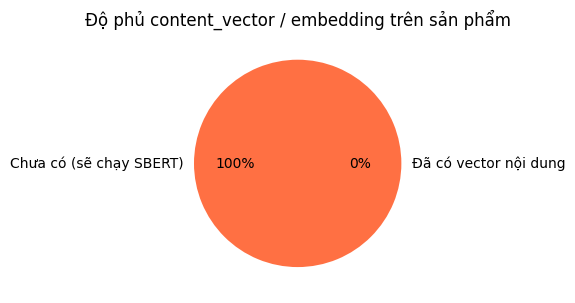

Tổng interaction: 2,918 | User trung bình: 52.1 tương tác/user (min=29, max=84)
Sản phẩm đã có vector nội dung: 0/398 | Chưa có: 398


In [4]:
import matplotlib.pyplot as plt

eda_interactions = list(interactions_col.find(
    {}, {"userId": 1, "productId": 1, "type": 1, "weight": 1, "createdAt": 1}
))
eda_df = pd.DataFrame(eda_interactions)
eda_df["type"] = eda_df["type"].fillna("(không có type)")
eda_df["createdAt"] = pd.to_datetime(eda_df["createdAt"], errors="coerce")

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1) Phân bố loại tương tác
type_counts = eda_df["type"].value_counts()
axes[0, 0].bar(type_counts.index, type_counts.values, color="steelblue")
axes[0, 0].set_title("Phân bố loại tương tác")
axes[0, 0].tick_params(axis="x", rotation=30)
axes[0, 0].grid(axis="y", linestyle="--", alpha=0.4)

# 2) Số tương tác theo user (histogram)
user_activity = eda_df.groupby("userId").size()
axes[0, 1].hist(user_activity.values, bins=20, color="darkorange", edgecolor="white")
axes[0, 1].set_title("Số tương tác trên mỗi user")
axes[0, 1].set_xlabel("Số tương tác")
axes[0, 1].set_ylabel("Số user")
axes[0, 1].grid(axis="y", linestyle="--", alpha=0.4)

# 3) Tương tác theo thời gian (nếu có createdAt hợp lệ)
if eda_df["createdAt"].notna().any():
    daily_counts = eda_df.dropna(subset=["createdAt"]).set_index("createdAt").resample("D").size()
    axes[1, 0].plot(daily_counts.index, daily_counts.values, color="mediumseagreen")
    axes[1, 0].set_title("Số tương tác theo ngày")
    axes[1, 0].tick_params(axis="x", rotation=30)
    axes[1, 0].grid(linestyle="--", alpha=0.4)
else:
    axes[1, 0].text(0.5, 0.5, "Không có createdAt hợp lệ", ha="center", va="center")
    axes[1, 0].set_title("Số tương tác theo ngày")

# 4) Top 10 sản phẩm được tương tác nhiều nhất
top_products = eda_df["productId"].astype(str).value_counts().head(10)
axes[1, 1].barh([p[-6:] for p in top_products.index][::-1], top_products.values[::-1], color="purple")
axes[1, 1].set_title("Top 10 sản phẩm được tương tác nhiều nhất\n(6 ký tự cuối _id)")
axes[1, 1].grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# Độ phủ dữ liệu: sản phẩm có/chưa có content_vector hoặc embedding
n_with_vec = products_col.count_documents({
    "$or": [{"content_vector": {"$exists": True, "$ne": None}}, {"embedding": {"$exists": True, "$ne": None}}]
})
n_without_vec = n_products - n_with_vec
fig2, ax2 = plt.subplots(figsize=(5, 4))
ax2.pie([n_with_vec, n_without_vec], labels=["Đã có vector nội dung", "Chưa có (sẽ chạy SBERT)"],
        autopct="%1.0f%%", colors=["#4CAF50", "#FF7043"])
ax2.set_title("Độ phủ content_vector / embedding trên sản phẩm")
plt.tight_layout()
plt.show()

print(f"Tổng interaction: {len(eda_df):,} | User trung bình: {user_activity.mean():.1f} tương tác/user "
      f"(min={user_activity.min()}, max={user_activity.max()})")
print(f"Sản phẩm đã có vector nội dung: {n_with_vec}/{n_products} | Chưa có: {n_without_vec}")


## Bước 2c: Phân tích độ đầy đủ dữ liệu theo từng trường (Field Completeness) — chọn `SPEC_FIELDS`

Trước khi ghép text đưa vào SBERT ở Bước 3, cần biết: mỗi trường cấu hình (`cpu`, `ram`, `gpu`, `storage`, `screen`...) có mặt ở bao nhiêu % sản phẩm? Sản phẩm nào đang thiếu trường quan trọng? `build_spec_text()` ở Bước 3 hiện đang **âm thầm bỏ qua** field nào `None` — nếu nhiều sản phẩm cùng thiếu 1 trường, SBERT dễ thấy chúng "giống nhau hơn thực tế".

Phân tích dưới đây giúp quyết định `SPEC_FIELDS` nên gồm trường nào (đủ dữ liệu, mang tính phân biệt) và trường nào nên loại/điền mặc định (quá thưa, dễ làm nhiễu embedding).

Tổng số sản phẩm: 398
        field              mongo_path  n_present  n_missing  pct_present
         name                    name        398          0        100.0
        price                   price        398          0        100.0
   brand_name                brand_id        398          0        100.0
category_name             category_id        398          0        100.0
          cpu      specifications.cpu        398          0        100.0
          gpu      specifications.gpu        398          0        100.0
          ram      specifications.ram        398          0        100.0
      storage  specifications.storage        398          0        100.0
      display  specifications.display        398          0        100.0
     features specifications.features        367         31         92.2
          npu      specifications.npu        159        239         39.9


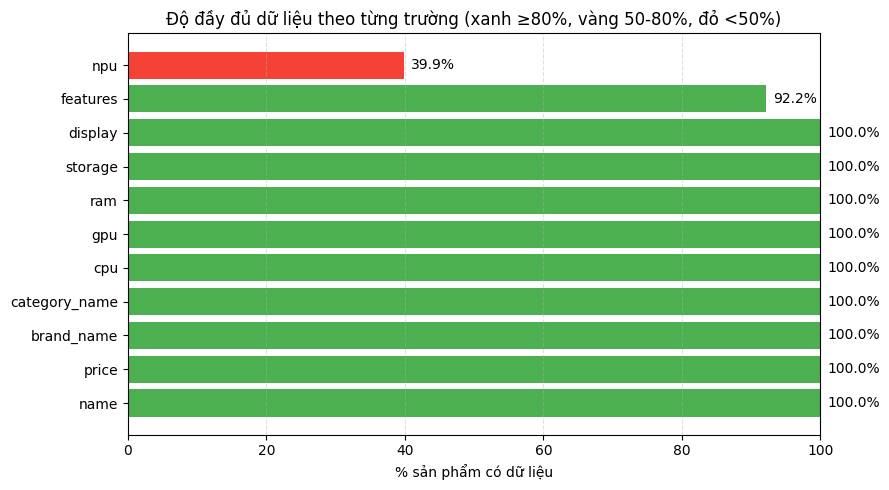

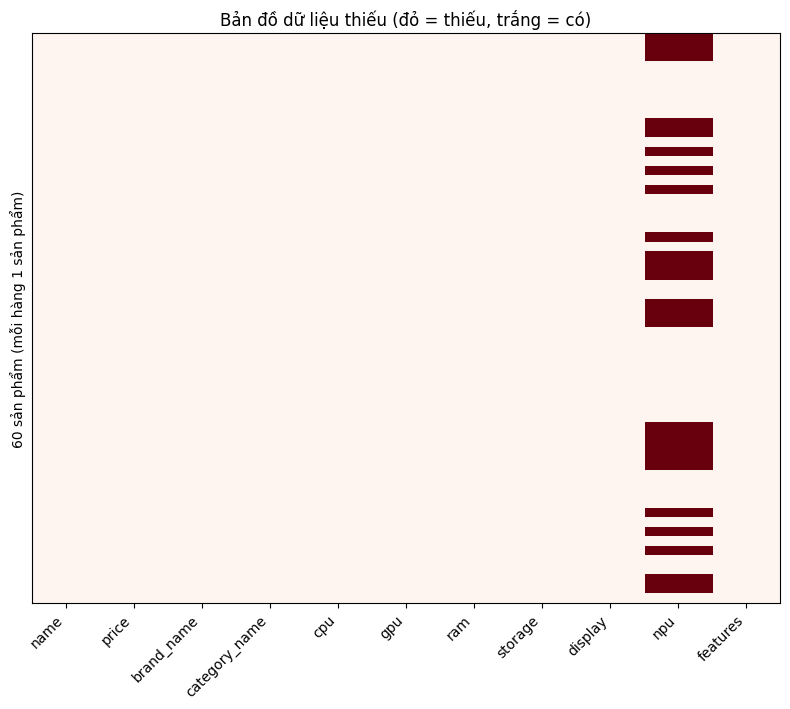


Số sản phẩm thiếu ít nhất 1 trong [cpu, gpu, ram]: 0/398

>>> Field đủ dữ liệu (≥ 70%), nên giữ trong SELECTED_FIELDS: ['name', 'price', 'brand_name', 'category_name', 'cpu', 'gpu', 'ram', 'storage', 'display', 'features']
>>> Field quá thưa (< 70%), cân nhắc loại hoặc điền mặc định: ['npu']
    (vd: npu/features thường mới có ở dòng cao cấp -> thiếu là bình thường,
     có thể vẫn giữ nhưng điền 'Không có' thay vì bỏ qua trong build_spec_text)


In [5]:
import pandas as pd
import numpy as np
from IPython.display import display

# ============================================================
# Field mapping — đúng theo schema thật của bạn:
# name/price ở root, brand/category là REFERENCE (brand_id/category_id),
# còn lại nằm trong nested object 'specifications'
# ============================================================
MONGO_SELECTED_FIELDS = [
    "name",
    "price",
    "brand_id",
    "category_id",
    "specifications.cpu",
    "specifications.gpu",
    "specifications.ram",
    "specifications.storage",
    "specifications.display",
    "specifications.npu",
    "specifications.features",
]

# Nhãn hiển thị đẹp cho biểu đồ (khớp ý nghĩa với SELECTED_FIELDS)
FIELD_LABELS = {
    "name": "name",
    "price": "price",
    "brand_id": "brand_name",
    "category_id": "category_name",
    "specifications.cpu": "cpu",
    "specifications.gpu": "gpu",
    "specifications.ram": "ram",
    "specifications.storage": "storage",
    "specifications.display": "display",
    "specifications.npu": "npu",
    "specifications.features": "features",
}

def get_nested(doc, dotted_path):
    """Đọc field theo đường dẫn có dấu chấm, vd 'specifications.cpu'. Trả None nếu bất kỳ cấp nào thiếu."""
    val = doc
    for part in dotted_path.split("."):
        if isinstance(val, dict) and part in val:
            val = val[part]
        else:
            return None
    return val

def is_missing(val):
    """Coi là thiếu nếu: không tồn tại, None, chuỗi rỗng/whitespace, hoặc list/dict rỗng."""
    if val is None:
        return True
    if isinstance(val, str) and val.strip() == "":
        return True
    if isinstance(val, (list, dict)) and len(val) == 0:
        return True
    return False

# Dùng lại all_products đã load ở Bước 3 nếu đã chạy, nếu chưa thì load mới
try:
    products_for_check = all_products
except NameError:
    products_for_check = list(products_col.find({}))

n_total = len(products_for_check)
print(f"Tổng số sản phẩm: {n_total}")

# --- 0) Resolve brand_id / category_id -> tên thật, để check "thiếu" đúng nghĩa ---
# (ObjectId luôn có giá trị -> phải join sang collection brands/categories mới biết
#  brand/category đó có thực sự tồn tại và có 'name' hay không)
brand_name_by_id = {}
category_name_by_id = {}
try:
    brand_name_by_id = {b["_id"]: b.get("name") for b in db["brands"].find({})}
except Exception as e:
    print(f"[Cảnh báo] Không đọc được collection 'brands' để resolve tên: {e}")
try:
    category_name_by_id = {c["_id"]: c.get("name") for c in db["categories"].find({})}
except Exception as e:
    print(f"[Cảnh báo] Không đọc được collection 'categories' để resolve tên: {e}")

def resolve_ref_name(id_or_ids, name_by_id):
    """Resolve 1 ObjectId hoặc 1 list ObjectId sang tên. Trả None nếu không resolve được gì."""
    if id_or_ids is None:
        return None
    if isinstance(id_or_ids, (list, tuple)):
        names = [name_by_id.get(i) for i in id_or_ids]
        names = [n for n in names if n]  # bỏ None/rỗng
        return ", ".join(names) if names else None
    return name_by_id.get(id_or_ids)

def get_field_value(doc, field):
    """Lấy giá trị 'thực' của field để check missing — brand_id/category_id được resolve ra tên
    (hỗ trợ cả trường hợp field là 1 ObjectId đơn hoặc 1 LIST ObjectId)."""
    if field == "brand_id":
        return resolve_ref_name(doc.get("brand_id"), brand_name_by_id)
    if field == "category_id":
        return resolve_ref_name(doc.get("category_id"), category_name_by_id)
    return get_nested(doc, field)

# --- 1) Bảng % đầy đủ theo từng trường ---
completeness_rows = []
for field in MONGO_SELECTED_FIELDS:
    n_missing = sum(is_missing(get_field_value(p, field)) for p in products_for_check)
    n_present = n_total - n_missing
    completeness_rows.append({
        "field": FIELD_LABELS[field],
        "mongo_path": field,
        "n_present": n_present,
        "n_missing": n_missing,
        "pct_present": round(100 * n_present / n_total, 1) if n_total else 0.0,
    })

completeness_df = pd.DataFrame(completeness_rows).sort_values("pct_present", ascending=False)
print(completeness_df.to_string(index=False))

# --- 2) Biểu đồ % đầy đủ theo trường ---
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#4CAF50" if p >= 80 else ("#FFC107" if p >= 50 else "#F44336")
          for p in completeness_df["pct_present"]]
ax.barh(completeness_df["field"], completeness_df["pct_present"], color=colors)
ax.set_xlabel("% sản phẩm có dữ liệu")
ax.set_title("Độ đầy đủ dữ liệu theo từng trường (xanh ≥80%, vàng 50-80%, đỏ <50%)")
ax.set_xlim(0, 100)
for i, (field, pct) in enumerate(zip(completeness_df["field"], completeness_df["pct_present"])):
    ax.text(pct + 1, i, f"{pct}%", va="center")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# --- 3) Heatmap: pattern thiếu dữ liệu theo từng sản phẩm x từng trường ---
sample_products = products_for_check[:60] if n_total > 60 else products_for_check
missing_matrix = np.array([
    [1 if is_missing(get_field_value(p, f)) else 0 for f in MONGO_SELECTED_FIELDS]
    for p in sample_products
])
fig2, ax2 = plt.subplots(figsize=(8, max(4, len(sample_products) * 0.12)))
ax2.imshow(missing_matrix, aspect="auto", cmap="Reds", vmin=0, vmax=1)
ax2.set_xticks(range(len(MONGO_SELECTED_FIELDS)))
ax2.set_xticklabels([FIELD_LABELS[f] for f in MONGO_SELECTED_FIELDS], rotation=45, ha="right")
ax2.set_yticks([])
ax2.set_ylabel(f"{len(sample_products)} sản phẩm (mỗi hàng 1 sản phẩm)")
ax2.set_title("Bản đồ dữ liệu thiếu (đỏ = thiếu, trắng = có)")
plt.tight_layout()
plt.show()

# --- 4) Danh sách các sản phẩm thiếu trường cấu hình quan trọng (cpu/gpu/ram) ---
CRITICAL_FIELDS = ["specifications.cpu", "specifications.gpu", "specifications.ram"]
missing_critical = []
for p in products_for_check:
    missing_here = [FIELD_LABELS[f] for f in CRITICAL_FIELDS if is_missing(get_field_value(p, f))]
    if missing_here:
        missing_critical.append({
            "_id": str(p.get("_id")),
            "name": p.get("name", "(không có tên)"),
            "thiếu": ", ".join(missing_here),
        })

print(f"\nSố sản phẩm thiếu ít nhất 1 trong [cpu, gpu, ram]: {len(missing_critical)}/{n_total}")
if missing_critical:
    display(pd.DataFrame(missing_critical).head(20))
    if len(missing_critical) > 20:
        print(f"... còn {len(missing_critical) - 20} sản phẩm khác (xem đầy đủ trong missing_critical)")

# --- 5) Đề xuất field nên đưa vào SELECTED_FIELDS (dựa trên ngưỡng đầy đủ) ---
THRESHOLD_PCT = 70  # field phải có dữ liệu ở >= 70% sản phẩm mới nên đưa vào text cho SBERT
recommended = completeness_df[completeness_df["pct_present"] >= THRESHOLD_PCT]["field"].tolist()
excluded = completeness_df[completeness_df["pct_present"] < THRESHOLD_PCT]["field"].tolist()

print(f"\n>>> Field đủ dữ liệu (≥ {THRESHOLD_PCT}%), nên giữ trong SELECTED_FIELDS: {recommended}")
if excluded:
    print(f">>> Field quá thưa (< {THRESHOLD_PCT}%), cân nhắc loại hoặc điền mặc định: {excluded}")
    print("    (vd: npu/features thường mới có ở dòng cao cấp -> thiếu là bình thường,")
    print("     có thể vẫn giữ nhưng điền 'Không có' thay vì bỏ qua trong build_spec_text)")

## Bước 3: Chạy SBERT — Sinh `content_vector` cho từng sản phẩm

Theo mục 2.2 của tài liệu: dùng Sentence-BERT để đọc thông số kỹ thuật (CPU/RAM/GPU/Màn hình...) và mã hoá thành vector 384 chiều. Model dùng: `all-MiniLM-L6-v2` (đúng 384 chiều như tài liệu nêu ví dụ).

**Giả định về field text mô tả sản phẩm:** notebook tự động ghép các field trong `SPEC_FIELDS` bên dưới nếu chúng tồn tại trên document — sửa lại danh sách này cho khớp đúng schema thật của bạn (`db.products.find_one()` để xem tên field chính xác).

Nếu sản phẩm **đã có sẵn** `content_vector` (hoặc field `embedding` cũ từ notebook trước) và `RECOMPUTE_CONTENT_VECTOR = False`, notebook sẽ **tái sử dụng** thay vì chạy lại SBERT — tiết kiệm thời gian, chỉ sản phẩm mới/thiếu vector mới được encode.

**ĐÃ SỬA (so với bản trước):** `SPEC_FIELDS`/`build_spec_text` giờ đọc đúng field lồng (`specifications.cpu/gpu/ram/...`) và resolve đúng `brand_id`/`category_id` sang tên thật, khớp với schema đã xác nhận ở Bước 2c — trước đó các field này bị đọc sai tên nên gần như luôn `None`.

In [6]:
from sentence_transformers import SentenceTransformer
import numpy as np

RECOMPUTE_CONTENT_VECTOR = True   # True = luôn chạy lại SBERT cho MỌI sản phẩm
# ĐÃ SỬA: field name khớp đúng schema thật đã xác nhận ở Bước 2c (Cell 9) —
# cpu/gpu/ram/... nằm trong specifications.*, brand/category là reference (brand_id/category_id).
# RECOMPUTE_CONTENT_VECTOR đặt True 1 lần để encode lại toàn bộ, vì content_vector cũ trong DB
# (nếu đã từng chạy bản build_spec_text SAI trước đó) đang gần như rỗng thông tin cấu hình.
SPEC_FIELDS = [
    "name", "price", "brand_id", "category_id",
    "specifications.cpu", "specifications.gpu", "specifications.ram",
    "specifications.storage", "specifications.display",
    "specifications.npu", "specifications.features",
]
SBERT_MODEL_NAME = "all-MiniLM-L6-v2"   # 384 chiều, khớp ví dụ trong tài liệu thiết kế

def build_spec_text(doc: dict) -> str:
    """Ghép các field cấu hình thành 1 câu text cho SBERT.
    Hỗ trợ field lồng (specifications.cpu) và field reference (brand_id/category_id -> tên thật)."""
    parts = []
    for field in SPEC_FIELDS:
        if field == "brand_id":
            val = resolve_ref_name(doc.get("brand_id"), brand_name_by_id)
            label = "brand"
        elif field == "category_id":
            val = resolve_ref_name(doc.get("category_id"), category_name_by_id)
            label = "category"
        else:
            val = get_nested(doc, field)
            label = field.split(".")[-1]   # "specifications.cpu" -> "cpu"
        if val is None or val == "":
            continue
        val_str = ", ".join(map(str, val)) if isinstance(val, list) else str(val)
        parts.append(f"{label}: {val_str}")
    return " | ".join(parts) if parts else str(doc.get("_id"))

all_products = list(products_col.find({}))
print(f"Tổng số sản phẩm trong `{PRODUCTS_COLL}`: {len(all_products)}")

if RECOMPUTE_CONTENT_VECTOR:
    to_encode = all_products
else:
    to_encode = [
        p for p in all_products
        if not (isinstance(p.get("content_vector"), (list, tuple)) and len(p["content_vector"]) > 0)
        and not (isinstance(p.get("embedding"), (list, tuple)) and len(p["embedding"]) > 0)
    ]

print(f"Số sản phẩm cần chạy SBERT mới: {len(to_encode)} "
      f"(RECOMPUTE_CONTENT_VECTOR={RECOMPUTE_CONTENT_VECTOR})")

new_content_vectors = {}
if to_encode:
    sbert_model = SentenceTransformer(SBERT_MODEL_NAME)
    texts = [build_spec_text(p) for p in to_encode]
    sample_idx = 0
    print(f"Ví dụ text đưa vào SBERT (sản phẩm #{sample_idx}):\n  {texts[sample_idx][:200]}")
    embeddings = sbert_model.encode(texts, show_progress_bar=True, normalize_embeddings=True)
    for p, emb in zip(to_encode, embeddings):
        new_content_vectors[str(p["_id"])] = emb.astype(np.float32).tolist()
    print(f"Đã sinh content_vector cho {len(new_content_vectors)} sản phẩm mới (384 chiều).")
else:
    print("Không có sản phẩm nào cần chạy SBERT — dùng lại content_vector/embedding đã có.")


Tổng số sản phẩm trong `products`: 398
Số sản phẩm cần chạy SBERT mới: 398 (RECOMPUTE_CONTENT_VECTOR=True)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (7 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Ví dụ text đưa vào SBERT (sản phẩm #0):
  name: Laptop Acer Nitro V 15 ProPanel ANV15-51-56D5 (i5-13420H/ GeForce RTX™ 3050/ 16GB/ 512GB/ Windows 11) | price: 21990000 | brand: Acer | category: Gaming | cpu: Intel® Core™ i5-13420H | gpu: GeFo


Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Đã sinh content_vector cho 398 sản phẩm mới (384 chiều).


## Bước 4: Chuẩn bị dữ liệu Interactions — encode, chia Train/Test

Gộp `content_vector` mới sinh (Bước 3) với dữ liệu sẵn có trên MongoDB (`content_vector` cũ hoặc `embedding` cũ), rồi tải + làm sạch interactions — có xử lý phòng thủ với dữ liệu thiếu/`None` (userId, productId, weight).

In [7]:
import scipy.sparse as sp
from sklearn.preprocessing import LabelEncoder, normalize

meta_rows = []
skipped_no_vector = 0
for p in all_products:
    pid = str(p["_id"])
    vec = new_content_vectors.get(pid) or p.get("content_vector") or p.get("embedding")
    if not isinstance(vec, (list, tuple)) or len(vec) == 0:
        skipped_no_vector += 1
        continue
    meta_rows.append({"product_id": pid, "content_vector": vec})

meta_df = pd.DataFrame(meta_rows)
if skipped_no_vector:
    print(f"Bỏ qua {skipped_no_vector} sản phẩm không có content_vector hợp lệ.")

vec_lens = meta_df["content_vector"].apply(len)
if vec_lens.nunique() > 1:
    common_len = int(vec_lens.mode()[0])
    n_bad = int((vec_lens != common_len).sum())
    print(f"CẢNH BÁO: {n_bad} content_vector có số chiều khác {common_len} — đã loại để tránh lỗi ghép ma trận.")
    meta_df = meta_df[vec_lens == common_len].reset_index(drop=True)

assert len(meta_df) > 0, "Không có sản phẩm nào có content_vector hợp lệ."

interactions = list(interactions_col.find(
    {"type": {"$ne": "remove_from_cart"}},
    {"userId": 1, "productId": 1, "weight": 1, "createdAt": 1}
))

review_rows = []
skipped_missing_ids = skipped_missing_weight = 0
for r in interactions:
    uid, pid = r.get("userId"), r.get("productId")
    if uid is None or pid is None:
        skipped_missing_ids += 1
        continue
    w = r.get("weight")
    if w is None:
        skipped_missing_weight += 1
        w = 0
    review_rows.append({
        "user_id": str(uid), "product_id": str(pid),
        "weight": max(w, 0), "timestamp": r.get("createdAt"),
    })

reviews_df = pd.DataFrame(review_rows)
if skipped_missing_ids:
    print(f"Bỏ qua {skipped_missing_ids} interaction thiếu userId/productId.")
if skipped_missing_weight:
    print(f"CẢNH BÁO: {skipped_missing_weight} interaction thiếu weight — coi weight=0.")

valid_products = set(meta_df["product_id"])
reviews_df = reviews_df[reviews_df["product_id"].isin(valid_products)].reset_index(drop=True)
print(f"Số dòng interaction hợp lệ: {len(reviews_df):,}")
assert len(reviews_df) > 0, "Không còn interaction hợp lệ nào sau khi lọc."

agg = reviews_df.groupby(["user_id", "product_id"]).agg(
    weight=("weight", "max"), timestamp=("timestamp", "max")
).reset_index()
assert len(agg) > 0, "Không có interaction hợp lệ nào để train."

user_enc, item_enc = LabelEncoder(), LabelEncoder()
agg["user_idx"] = user_enc.fit_transform(agg["user_id"])
agg["item_idx"] = item_enc.fit_transform(agg["product_id"])
n_users = agg["user_idx"].nunique()
n_items = agg["item_idx"].nunique()
print(f"n_users={n_users}, n_items={n_items}, n_interactions={len(agg):,}")

agg = agg.sort_values(["user_idx", "timestamp"])
user_counts = agg.groupby("user_idx").size()
testable_users = user_counts[user_counts >= 2].index
test_rows = agg[agg["user_idx"].isin(testable_users)].groupby("user_idx").tail(1)
train_rows = agg.drop(test_rows.index)
print(f"Train: {len(train_rows):,} | Test: {len(test_rows):,} ({len(testable_users)} user trainable)")

item_id_order = item_enc.classes_
meta_indexed = meta_df.set_index("product_id").reindex(item_id_order)
content_vector_matrix = np.vstack(meta_indexed["content_vector"].values).astype(np.float32)
content_vector_matrix = normalize(content_vector_matrix)
CONTENT_DIM = content_vector_matrix.shape[1]
print(f"content_vector_matrix: {content_vector_matrix.shape} ({CONTENT_DIM} chiều)")


Số dòng interaction hợp lệ: 2,918
n_users=56, n_items=398, n_interactions=1,704
Train: 1,648 | Test: 56 (56 user trainable)
content_vector_matrix: (398, 384) (384 chiều)


## Bước 4b: Trực quan hoá không gian `content_vector`

Giảm chiều `content_vector` (384 chiều) xuống 2D bằng PCA để xem trực quan các sản phẩm có cấu hình gần nhau có thực sự nằm gần nhau trong không gian vector hay không — kiểm tra nhanh chất lượng embedding trước khi dùng để retrieval.

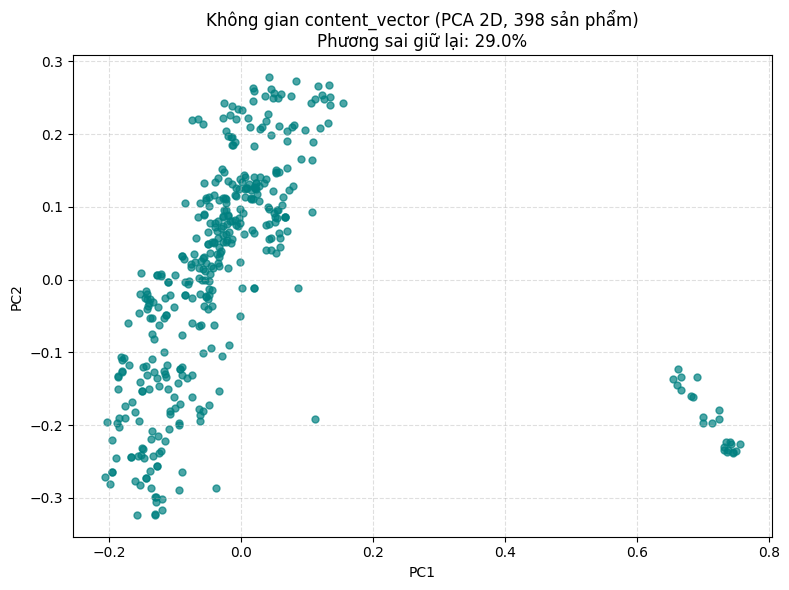

Nếu các điểm tụ thành nhiều cụm rõ rệt → content_vector đang phân biệt tốt các nhóm sản phẩm khác nhau (tốt cho Content-Based/Cold-Start). Nếu các điểm trộn lẫn hỗn loạn, cân nhắc kiểm tra lại SPEC_FIELDS ở Bước 3 (có thể đang thiếu thông tin phân biệt sản phẩm).


In [8]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
content_2d = pca.fit_transform(content_vector_matrix)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(content_2d[:, 0], content_2d[:, 1], s=25, alpha=0.7, color="teal")
ax.set_title(f"Không gian content_vector (PCA 2D, {n_items} sản phẩm)\n"
             f"Phương sai giữ lại: {pca.explained_variance_ratio_.sum():.1%}")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.grid(linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("Nếu các điểm tụ thành nhiều cụm rõ rệt → content_vector đang phân biệt tốt các nhóm sản "
      "phẩm khác nhau (tốt cho Content-Based/Cold-Start). Nếu các điểm trộn lẫn hỗn loạn, cân nhắc "
      "kiểm tra lại SPEC_FIELDS ở Bước 3 (có thể đang thiếu thông tin phân biệt sản phẩm).")


## Bước 5: Chạy ALS — train trên tập Train (để đánh giá công bằng)

Theo mục 2.1: ALS (Alternating Least Squares) cho Implicit Feedback, phân rã ma trận User-Item thành Latent Factors → sinh `cf_vector`. Thử vài cấu hình `factors`/`regularization` để tránh overfit (factors quá lớn so với lượng dữ liệu thực tế dễ học vẹt).

In [9]:
from implicit.als import AlternatingLeastSquares

ALPHA_CONFIDENCE = 3.0   # hệ số confidence = 1 + ALPHA_CONFIDENCE * weight (chuẩn ALS-implicit)
ALS_CONFIGS = [
    {"factors": 8,  "regularization": 0.3, "iterations": 20},
    {"factors": 16, "regularization": 0.3, "iterations": 20},
    {"factors": 32, "regularization": 0.1, "iterations": 20},
]

train_conf = 1 + ALPHA_CONFIDENCE * train_rows["weight"].values
train_matrix = sp.csr_matrix(
    (train_conf, (train_rows["user_idx"], train_rows["item_idx"])), shape=(n_users, n_items)
)

als_candidates = {}
for cfg in ALS_CONFIGS:
    key = f"f{cfg['factors']}_r{cfg['regularization']}"
    m = AlternatingLeastSquares(factors=cfg["factors"], regularization=cfg["regularization"],
                                 iterations=cfg["iterations"], random_state=42)
    m.fit(train_matrix)
    als_candidates[key] = (m, cfg)
    print(f"Đã train ALS({key})")


/usr/local/lib/python3.12/dist-packages/implicit/gpu/__init__.py:28: UserWarning: Disabling GPU support because of 'libcublas.so.13: cannot open shared object file: No such file or directory'
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/implicit/cpu/als.py:96: RuntimeWarning: OpenBLAS is configured to use 4 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


  0%|          | 0/20 [00:00<?, ?it/s]

Đã train ALS(f8_r0.3)


  0%|          | 0/20 [00:00<?, ?it/s]

Đã train ALS(f16_r0.3)


  0%|          | 0/20 [00:00<?, ?it/s]

Đã train ALS(f32_r0.1)


## Bước 6: Đánh giá riêng biệt CF và Content (không gộp)

Đúng tinh thần thiết kế — 2 nhánh độc lập, nên đánh giá độc lập bằng bộ metric R@5/R@10/R@20/NDCG@10/Coverage/Diversity, chọn cấu hình ALS tốt nhất.

=== Đánh giá Content-Based (content_vector) ===
                Nhánh      R@5     R@10     R@20  NDCG@10  Coverage  Diversity
Content-Based (SBERT) 0.017857 0.017857 0.071429 0.011267  0.346734   0.076518

=== Đánh giá từng cấu hình ALS (cf_vector) ===
Cấu hình ALS      R@5     R@10     R@20  NDCG@10  Coverage  Diversity
     f8_r0.3 0.017857 0.053571 0.071429 0.022275  0.620603   0.203414
    f32_r0.1 0.017857 0.035714 0.125000 0.014051  0.733668   0.214340
    f16_r0.3 0.000000 0.017857 0.053571 0.006361  0.706030   0.211906

>>> Cấu hình ALS tốt nhất: f8_r0.3 → dùng để sinh cf_vector cuối cùng.


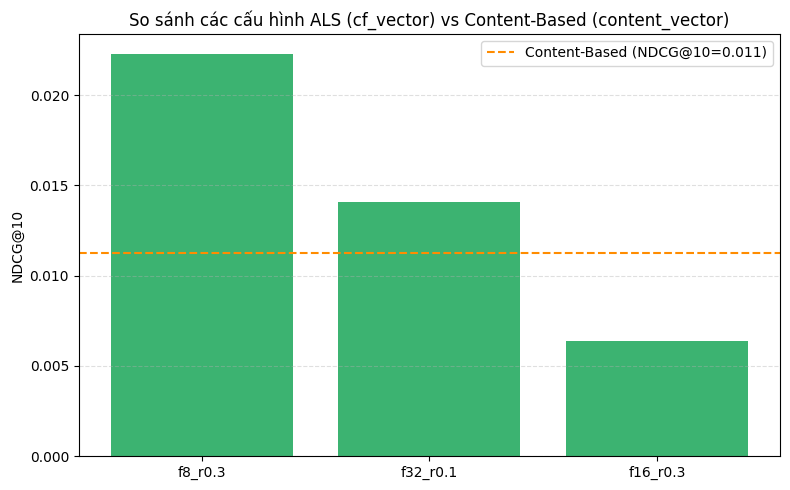

In [10]:
user_train_items = train_rows.groupby("user_idx")["item_idx"].apply(set).to_dict()
all_items = np.arange(n_items)
K_LIST = [5, 10, 20]

def evaluate_model_full_catalog(score_fn, k_list=K_LIST):
    hits_at_k = {k: [] for k in k_list}
    ndcgs, topk_per_user = [], {}
    for _, row in test_rows.iterrows():
        u, pos = int(row["user_idx"]), int(row["item_idx"])
        seen = user_train_items.get(u, set())
        mask = np.ones(n_items, dtype=bool)
        if seen:
            mask[np.fromiter(seen, dtype=int, count=len(seen))] = False
        mask[pos] = True  # đảm bảo item test luôn có mặt trong candidate
        candidates = all_items[mask]
        scores = score_fn(u, candidates)
        ranked = candidates[np.argsort(-scores)]
        rank = int(np.where(ranked == pos)[0][0]) + 1
        for k in k_list:
            hits_at_k[k].append(1 if rank <= k else 0)
        ndcgs.append(1 / np.log2(rank + 1) if rank <= 10 else 0.0)
        topk_per_user[u] = ranked[:10]

    recall_at_k = {k: float(np.mean(hits_at_k[k])) for k in k_list}
    ndcg10 = float(np.mean(ndcgs))
    all_recommended = set()
    for items in topk_per_user.values():
        all_recommended.update(items.tolist())
    coverage = len(all_recommended) / n_items

    div_scores = []
    for items in topk_per_user.values():
        if len(items) < 2:
            continue
        vecs = content_vector_matrix[items]
        sim = vecs @ vecs.T
        iu = np.triu_indices(len(items), k=1)
        div_scores.append(1 - (sim[iu].mean() if len(iu[0]) > 0 else 0.0))
    diversity = float(np.mean(div_scores)) if div_scores else 0.0

    return {"R@5": recall_at_k[5], "R@10": recall_at_k[10], "R@20": recall_at_k[20],
            "NDCG@10": ndcg10, "Coverage": coverage, "Diversity": diversity}

def make_score_cf(model_obj):
    def _score(u, c):
        return model_obj.item_factors[c] @ model_obj.user_factors[u]
    return _score

# Vector khẩu vị nội dung của user (chỉ để ĐÁNH GIÁ — công thức giống mục 3.3 của tài liệu:
# trung bình cộng có trọng số các content_vector sản phẩm user đã tương tác trong tập Train)
train_weight_matrix = sp.csr_matrix(
    (train_rows["weight"].values, (train_rows["user_idx"], train_rows["item_idx"])),
    shape=(n_users, n_items)
)
user_content_profile_train = normalize(train_weight_matrix @ content_vector_matrix)

# Định nghĩa SAU khi user_content_profile_train đã có, để thứ tự đọc code khớp thứ tự phụ thuộc
def score_content(u, c):
    return content_vector_matrix[c] @ user_content_profile_train[u]

print("=== Đánh giá Content-Based (content_vector) ===")
content_report = evaluate_model_full_catalog(score_content)
print(pd.DataFrame([{"Nhánh": "Content-Based (SBERT)", **content_report}]).to_string(index=False))

print("\n=== Đánh giá từng cấu hình ALS (cf_vector) ===")
als_reports = []
for key, (m, cfg) in als_candidates.items():
    rep = evaluate_model_full_catalog(make_score_cf(m))
    als_reports.append({"Cấu hình ALS": key, **rep})
als_report_df = pd.DataFrame(als_reports).sort_values("NDCG@10", ascending=False).reset_index(drop=True)
print(als_report_df.to_string(index=False))

best_als_key = als_report_df.iloc[0]["Cấu hình ALS"]
best_als_model, best_als_cfg = als_candidates[best_als_key]
print(f"\n>>> Cấu hình ALS tốt nhất: {best_als_key} → dùng để sinh cf_vector cuối cùng.")

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(als_report_df["Cấu hình ALS"], als_report_df["NDCG@10"], color="mediumseagreen")
ax.axhline(content_report["NDCG@10"], color="darkorange", linestyle="--",
           label=f"Content-Based (NDCG@10={content_report['NDCG@10']:.3f})")
ax.set_ylabel("NDCG@10")
ax.set_title("So sánh các cấu hình ALS (cf_vector) vs Content-Based (content_vector)")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


## Bước 7: Mô phỏng Re-ranking để đề xuất α mặc định

Theo mục 2.3, công thức `Score_Final = α×Score_CF + (1-α)×Score_Content` chạy **ở Backend lúc phục vụ**, không lưu sẵn. Ở đây notebook chỉ **thử nghiệm offline** nhiều giá trị α trên tập Test để **đề xuất một giá trị α mặc định hợp lý** cho cấu hình API/Backend (ví dụ tài liệu nêu α=0.7) — **không ghi bất kỳ vector gộp nào vào MongoDB**.

 alpha      R@5     R@10     R@20  NDCG@10  Coverage  Diversity
   0.1 0.017857 0.017857 0.053571 0.017857  0.386935   0.087957
   0.2 0.017857 0.035714 0.035714 0.012070  0.439698   0.102012
   0.3 0.000000 0.035714 0.053571 0.012722  0.472362   0.112949
   0.4 0.017857 0.053571 0.053571 0.020004  0.515075   0.121253
   0.5 0.035714 0.035714 0.053571 0.016619  0.537688   0.129252
   0.6 0.035714 0.035714 0.053571 0.018175  0.560302   0.140322
   0.7 0.035714 0.035714 0.071429 0.024765  0.587940   0.152218
   0.8 0.017857 0.035714 0.071429 0.017219  0.603015   0.171353
   0.9 0.017857 0.053571 0.071429 0.022018  0.597990   0.185494

>>> α đề xuất (NDCG@10 cao nhất trên tập Test): 0.7
LƯU Ý: số user trainable còn nhỏ — coi giá trị α này là điểm khởi đầu hợp lý để cấu hình API, không phải con số tối ưu tuyệt đối. Nên xem lại khi có thêm dữ liệu thật.


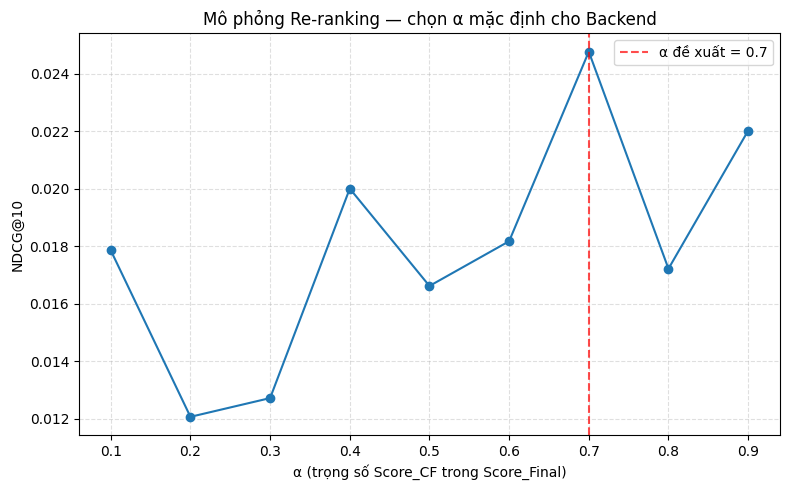

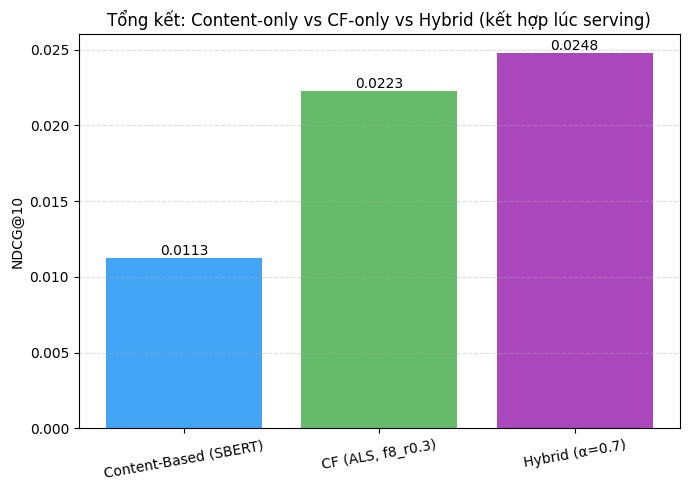

In [11]:

def minmax_norm(x):
    lo, hi = x.min(), x.max()
    return np.zeros_like(x) if hi - lo < 1e-9 else (x - lo) / (hi - lo)

score_cf_best = make_score_cf(best_als_model)

def score_final(u, c, alpha):
    cf_val = minmax_norm(score_cf_best(u, c))
    content_val = minmax_norm(score_content(u, c))
    return alpha * cf_val + (1 - alpha) * content_val

alpha_grid = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
alpha_rows = []
for alpha in alpha_grid:
    rep = evaluate_model_full_catalog(lambda u, c, a=alpha: score_final(u, c, a))
    alpha_rows.append({"alpha": alpha, **rep})

alpha_df = pd.DataFrame(alpha_rows)
print(alpha_df.to_string(index=False))

best_alpha_row = alpha_df.sort_values("NDCG@10", ascending=False).iloc[0]
SUGGESTED_ALPHA = float(best_alpha_row["alpha"])
print(f"\n>>> α đề xuất (NDCG@10 cao nhất trên tập Test): {SUGGESTED_ALPHA}")

if n_trainable_users < 100:
    print("LƯU Ý: số user trainable còn nhỏ — coi giá trị α này là điểm khởi đầu hợp lý để cấu "
          "hình API, không phải con số tối ưu tuyệt đối. Nên xem lại khi có thêm dữ liệu thật.")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(alpha_df["alpha"], alpha_df["NDCG@10"], marker="o")
ax.axvline(SUGGESTED_ALPHA, color="red", linestyle="--", alpha=0.7, label=f"α đề xuất = {SUGGESTED_ALPHA}")
ax.set_xlabel("α (trọng số Score_CF trong Score_Final)")
ax.set_ylabel("NDCG@10")
ax.set_title("Mô phỏng Re-ranking — chọn α mặc định cho Backend")
ax.legend()
ax.grid(linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# --- Biểu đồ tổng kết: Content-only vs CF-only vs Hybrid (α đề xuất) ---
hybrid_report_at_best = alpha_df[alpha_df["alpha"] == SUGGESTED_ALPHA].iloc[0]
summary_df = pd.DataFrame([
    {"Nhánh": "Content-Based (SBERT)", "NDCG@10": content_report["NDCG@10"]},
    {"Nhánh": f"CF (ALS, {best_als_key})", "NDCG@10": als_report_df.iloc[0]["NDCG@10"]},
    {"Nhánh": f"Hybrid (α={SUGGESTED_ALPHA})", "NDCG@10": hybrid_report_at_best["NDCG@10"]},
])
fig2, ax2 = plt.subplots(figsize=(7, 5))
bars = ax2.bar(summary_df["Nhánh"], summary_df["NDCG@10"], color=["#42A5F5", "#66BB6A", "#AB47BC"])
for bar, val in zip(bars, summary_df["NDCG@10"]):
    ax2.text(bar.get_x() + bar.get_width() / 2, val, f"{val:.4f}", ha="center", va="bottom")
ax2.set_ylabel("NDCG@10")
ax2.set_title("Tổng kết: Content-only vs CF-only vs Hybrid (kết hợp lúc serving)")
ax2.tick_params(axis="x", rotation=10)
ax2.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


## Bước 8: Train lại trên TOÀN BỘ dữ liệu (bản `cf_vector` sẽ deploy)

Dùng cấu hình ALS tốt nhất ở Bước 6, train lại trên **toàn bộ** `interactions` (không chia train/test) để có `cf_vector` chính thức cho mọi sản phẩm có tương tác.

In [12]:
full_conf = 1 + ALPHA_CONFIDENCE * agg["weight"].values
full_matrix = sp.csr_matrix(
    (full_conf, (agg["user_idx"], agg["item_idx"])), shape=(n_users, n_items)
)

final_als_model = AlternatingLeastSquares(
    factors=best_als_cfg["factors"], regularization=best_als_cfg["regularization"],
    iterations=best_als_cfg["iterations"], random_state=42
)
final_als_model.fit(full_matrix)

print(f"Đã train ALS cuối cùng ({best_als_key}) trên toàn bộ {len(agg):,} interaction.")
print("item_factors (cf_vector):", final_als_model.item_factors.shape,
      "| user_factors:", final_als_model.user_factors.shape)

item_id_order_full = item_enc.classes_


  0%|          | 0/20 [00:00<?, ?it/s]

Đã train ALS cuối cùng (f8_r0.3) trên toàn bộ 1,704 interaction.
item_factors (cf_vector): (398, 8) | user_factors: (56, 8)


## Bước 9: Lưu `cf_vector` + `content_vector` vào MongoDB Atlas (KHÔNG gộp)

Đúng mục 3.2.3 của tài liệu — ghi `cf_vector` (từ ALS) và `content_vector` (từ SBERT) ngược lại vào từng document sản phẩm, giữ **riêng biệt**, kèm metadata để backend biết cấu hình lúc train (và `α` đề xuất, chỉ mang tính tham khảo cấu hình API — không dùng để gộp vector).

`DRY_RUN = True` mặc định — chỉ in thử số lượng sẽ cập nhật, **chưa ghi gì**. Đặt `False` để ghi thật.

In [13]:
from pymongo import UpdateOne
from bson import ObjectId
import datetime as dt

DRY_RUN = True
trained_at = dt.datetime.utcnow()

metadata = {
    "cf_type": "ALS", "cf_factors": best_als_cfg["factors"],
    "cf_regularization": best_als_cfg["regularization"], "alpha_confidence": ALPHA_CONFIDENCE,
    "content_model": SBERT_MODEL_NAME, "suggested_alpha": SUGGESTED_ALPHA, "trained_at": trained_at,
}

# --- cf_vector: chỉ sản phẩm có tương tác (n_items) mới có ---
cf_ops = [
    UpdateOne(
        {"_id": ObjectId(pid)},
        {"$set": {"cf_vector": final_als_model.item_factors[i].tolist(), "cf_metadata": metadata}}
    )
    for i, pid in enumerate(item_id_order_full)
]

# --- content_vector: MỌI sản phẩm có vector hợp lệ ở Bước 3/4 (kể cả sản phẩm chưa có tương tác) ---
content_ops = [
    UpdateOne(
        {"_id": ObjectId(row["product_id"])},
        {"$set": {"content_vector": row["content_vector"],
                   "content_metadata": {"model": SBERT_MODEL_NAME, "trained_at": trained_at}}}
    )
    for _, row in meta_df.iterrows()
    if row["product_id"] in new_content_vectors   # chỉ ghi lại những cái MỚI sinh ở Bước 3
]

print(f"Sẽ cập nhật cf_vector cho {len(cf_ops)} sản phẩm.")
print(f"Sẽ cập nhật content_vector cho {len(content_ops)} sản phẩm (mới sinh ở Bước 3).")

if DRY_RUN:
    print("\nDRY_RUN=True — CHƯA ghi gì vào MongoDB. Đặt DRY_RUN=False rồi chạy lại để ghi thật.")
else:
    if cf_ops:
        result_cf = products_col.bulk_write(cf_ops)
        print(f"Đã cập nhật cf_vector cho {result_cf.modified_count} sản phẩm.")
    if content_ops:
        result_content = products_col.bulk_write(content_ops)
        print(f"Đã cập nhật content_vector cho {result_content.modified_count} sản phẩm.")
    print(f"\n>>> Cấu hình đề xuất cho Backend (Node.js): alpha = {SUGGESTED_ALPHA} "
          "(dùng khi tính Score_Final ở bước Re-ranking, KHÔNG lưu vào DB).")


Sẽ cập nhật cf_vector cho 398 sản phẩm.
Sẽ cập nhật content_vector cho 398 sản phẩm (mới sinh ở Bước 3).

DRY_RUN=True — CHƯA ghi gì vào MongoDB. Đặt DRY_RUN=False rồi chạy lại để ghi thật.


/tmp/ipykernel_23/1858239390.py:6: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  trained_at = dt.datetime.utcnow()


## Bước 10: Kích hoạt Vector Search Index trên Atlas

Theo mục 3.2.3: *"Kích hoạt Vector Search Index để Database sẵn sàng cho việc truy vấn không gian siêu tốc."* Thử tạo qua driver (`pymongo>=4.7`, cần Atlas, hoạt động cả trên tier M0/M2/M5). Nếu cluster/quyền hạn không cho phép tạo qua code, notebook in ra sẵn JSON để bạn dán thủ công vào **Atlas UI → Search → Create Search Index → JSON Editor**.

In [14]:
import json
from pymongo.operations import SearchIndexModel

content_index_def = {
    "fields": [
        {"type": "vector", "path": "content_vector", "numDimensions": CONTENT_DIM, "similarity": "cosine"},
    ]
}
cf_index_def = {
    "fields": [
        {"type": "vector", "path": "cf_vector", "numDimensions": best_als_cfg["factors"], "similarity": "cosine"},
    ]
}

if DRY_RUN:
    print("DRY_RUN=True — chỉ in thử định nghĩa Index, CHƯA gửi yêu cầu tạo.")
else:
    try:
        products_col.create_search_index(
            SearchIndexModel(definition=content_index_def, name="content_vector_index", type="vectorSearch")
        )
        products_col.create_search_index(
            SearchIndexModel(definition=cf_index_def, name="cf_vector_index", type="vectorSearch")
        )
        print("Đã gửi yêu cầu tạo 2 Vector Search Index (content_vector_index, cf_vector_index). "
              "Atlas cần vài phút để build xong — kiểm tra trạng thái ở tab Atlas Search.")
    except Exception as e:
        print("Không tự tạo được Index qua driver:", e)
        print("Tạo thủ công: Atlas UI → Search → Create Search Index → JSON Editor, dán JSON dưới đây:")

print("\n--- content_vector_index ---")
print(json.dumps(content_index_def, indent=2, ensure_ascii=False))
print("\n--- cf_vector_index ---")
print(json.dumps(cf_index_def, indent=2, ensure_ascii=False))


DRY_RUN=True — chỉ in thử định nghĩa Index, CHƯA gửi yêu cầu tạo.

--- content_vector_index ---
{
  "fields": [
    {
      "type": "vector",
      "path": "content_vector",
      "numDimensions": 384,
      "similarity": "cosine"
    }
  ]
}

--- cf_vector_index ---
{
  "fields": [
    {
      "type": "vector",
      "path": "cf_vector",
      "numDimensions": 8,
      "similarity": "cosine"
    }
  ]
}


## Bước 11: Lưu model xuống local để tái sử dụng + tải xuống ngay

Đóng gói `final_als_model` (cf_vector) + `content_vector_matrix` + encoder + `SUGGESTED_ALPHA` vào một file `.joblib` — dùng để test lại pipeline mà không cần train lại, và tải ngay trong lúc notebook đang chạy (không cần đợi Kaggle Commit).

In [15]:
import joblib, shutil, os
from IPython.display import FileLink, display

os.makedirs("artifacts/phase2_giai_doan_2", exist_ok=True)

bundle = {
    "cf_model": final_als_model,
    "content_vector_matrix": content_vector_matrix,
    "user_enc": user_enc,
    "item_enc": item_enc,
    "config": {
        "cf_type": "ALS",
        "cf_factors": best_als_cfg["factors"],
        "cf_regularization": best_als_cfg["regularization"],
        "suggested_alpha": SUGGESTED_ALPHA,
        "content_model": SBERT_MODEL_NAME,
    },
}
joblib.dump(bundle, "artifacts/phase2_giai_doan_2/giai_doan_2_model.joblib")
print("Đã lưu artifacts/phase2_giai_doan_2/giai_doan_2_model.joblib")

# --- Backup rời từng thành phần (npy/json) — dễ khôi phục từng phần nếu cần, không phụ thuộc joblib ---
np.save("artifacts/phase2_giai_doan_2/cf_vector_items.npy", final_als_model.item_factors)
np.save("artifacts/phase2_giai_doan_2/content_vector_items.npy", content_vector_matrix)
with open("artifacts/phase2_giai_doan_2/item_id_order.json", "w") as f:
    json.dump(list(item_id_order_full), f)
with open("artifacts/phase2_giai_doan_2/final_config.json", "w") as f:
    json.dump({
        "cf_type": "ALS", "cf_factors": best_als_cfg["factors"],
        "cf_regularization": best_als_cfg["regularization"],
        "content_model": SBERT_MODEL_NAME, "content_dim": CONTENT_DIM,
        "suggested_alpha": SUGGESTED_ALPHA,
        "ndcg10_content_only": content_report["NDCG@10"],
        "ndcg10_cf_only": float(als_report_df.iloc[0]["NDCG@10"]),
        "ndcg10_hybrid_suggested_alpha": float(hybrid_report_at_best["NDCG@10"]),
    }, f, indent=2, ensure_ascii=False)
print("Đã backup cf_vector_items.npy, content_vector_items.npy, item_id_order.json, final_config.json")

zip_path = shutil.make_archive("phase2_giai_doan_2", "zip", "artifacts/phase2_giai_doan_2")
display(FileLink("artifacts/phase2_giai_doan_2/giai_doan_2_model.joblib"))
display(FileLink(zip_path))


Đã lưu artifacts/phase2_giai_doan_2/giai_doan_2_model.joblib
Đã backup cf_vector_items.npy, content_vector_items.npy, item_id_order.json, final_config.json


/kaggle/working/artifacts/phase2_giai_doan_2/giai_doan_2_model.joblib

/kaggle/working/phase2_giai_doan_2.zip

## Bước 12: Ví dụ mô phỏng luồng Online Serving (Retrieval + Re-ranking)

Logic thật sự chạy ở Backend Node.js (Giai đoạn 4), nhưng để kiểm chứng 2 vector vừa sinh hoạt động đúng, notebook mô phỏng lại bằng Python:

1. **Retrieval** (giả lập `$vectorSearch`): lấy Top-50 gần nhất theo `content_vector`.
2. **Re-ranking**: chấm lại bằng `Score_Final = α×CF + (1-α)×Content` trên Top-50 đó, trả về Top-10.

Kèm ví dụ **Cold-Start** (mục 4 của tài liệu): user mới click 1 sản phẩm → dùng luôn `cf_vector`/`content_vector` của sản phẩm đó làm Session Vector.

In [16]:
def _minmax(x):
    lo, hi = x.min(), x.max()
    return np.zeros_like(x) if hi - lo < 1e-9 else (x - lo) / (hi - lo)

def recommend_related(product_id: str, top_n: int = 10, retrieval_k: int = 50, alpha: float = None):
    """Mô phỏng: Retrieval (content_vector, giả lập $vectorSearch) -> Re-ranking (Score_Final)."""
    alpha = SUGGESTED_ALPHA if alpha is None else alpha
    if product_id not in item_enc.classes_:
        raise ValueError(f"product_id {product_id} chưa có content_vector/cf_vector đã train.")
    idx = item_enc.transform([product_id])[0]

    # --- Retrieval: top-K theo content_vector (cosine, vì đã normalize) ---
    content_sims_full = content_vector_matrix @ content_vector_matrix[idx]
    content_sims_full[idx] = -np.inf
    retrieval_idx = np.argsort(-content_sims_full)[:retrieval_k]

    # --- Re-ranking: Score_Final = alpha * CF + (1 - alpha) * Content, chỉ trên tập đã retrieval ---
    content_scores = _minmax(content_sims_full[retrieval_idx])
    cf_vec = final_als_model.item_factors[idx]
    cf_raw = final_als_model.item_factors[retrieval_idx] @ cf_vec
    cf_scores = _minmax(cf_raw)
    final_scores = alpha * cf_scores + (1 - alpha) * content_scores

    top_local = np.argsort(-final_scores)[:top_n]
    top_idx = retrieval_idx[top_local]
    return [
        {"product_id": item_enc.inverse_transform([i])[0], "score": float(final_scores[j])}
        for j, i in zip(top_local, top_idx)
    ]

def cold_start_session_vector(clicked_product_id: str):
    """Mục 4 tài liệu: cú click đầu tiên -> copy cf_vector + content_vector làm Session Vector."""
    idx = item_enc.transform([clicked_product_id])[0]
    return {
        "content_vector": content_vector_matrix[idx].tolist(),
        "cf_vector": final_als_model.item_factors[idx].tolist(),
    }

# Ví dụ chạy thử:
# sample_pid = item_id_order_full[0]
# print(recommend_related(sample_pid, top_n=5))
# print(cold_start_session_vector(sample_pid))
print("Đã định nghĩa recommend_related() và cold_start_session_vector() — ví dụ minh hoạ luồng "
      "Retrieval + Re-ranking (Giai đoạn 4) và Cold-Start (mục 4) của tài liệu thiết kế.")


Đã định nghĩa recommend_related() và cold_start_session_vector() — ví dụ minh hoạ luồng Retrieval + Re-ranking (Giai đoạn 4) và Cold-Start (mục 4) của tài liệu thiết kế.
